# Зворотна перевірка моделей: Scene_07 → Scene_05

Перевіряємо, наскільки результат залежить від вибору навчальної сцени. **Навчаємо на Scene_07, оцінюємо на Scene_05.** Це додатковий дослід на двох уже використаних сценах; остаточна перевірка на Scene_21 залишається окремою.

Три варіанти незмінні: стала частота успіху; логістична регресія за геометричними ознаками; така сама регресія з доданою щільністю SIFT-точок карти. Логістична регресія перетворює числові ознаки на ймовірність події. Подія: SIFT прийняв прив’язку з похибкою до 3 м.

Результат не гарантовано покращиться: нових ознак або сцен цей дослід не додає. Він перевіряє перенесення між сценами у зворотному напрямку.

Вручну скопіюйте оновлений `scripts/pipeline/chance_constrained/visual_map_localization/outcome_model.py` і цей notebook у Drive. Використовуються ті самі `features.csv`, `labels.csv`, `feature_spec.json` з `vml/working-review-v1`. Повторно завантажувати ZIP або запускати SIFT не потрібно. GPU не потрібен.


In [1]:
import os
from pathlib import Path
if not os.environ.get('COLAB_RELEASE_TAG') or not Path('/content').is_dir():
    raise RuntimeError('Use a hosted Google Colab runtime, not a local runtime.')
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Перевірити таблиці та напрямок

Початкові позначення розподілу в таблицях не змінюємо. Новий код змінює лише вибір рядків у пам’яті та явно записує напрямок у `run.json`. Масштабування ознак обчислюється лише за Scene_07.

Результати записуються в нову папку `correct-fix-reverse-v1`. Папку першого досліду залишаємо без змін. Один каталог результатів має використовувати лише одна сесія.


In [2]:
REPO_ROOT = Path('/content/drive/MyDrive/PhD/proj')
DATASET_DIR = REPO_ROOT / 'vml/working-review-v1'
OUTPUT_DIR = REPO_ROOT / 'vml/correct-fix-reverse-v1'
import sys, importlib, json
sys.path.insert(0, str(REPO_ROOT))
importlib.invalidate_caches()
modeling = importlib.import_module('scripts.pipeline.chance_constrained.visual_map_localization.outcome_model')
importlib.reload(modeling)
spec, rows, y, original_train = modeling.load_tables(DATASET_DIR)
for label, mask in [('training_Scene_07', ~original_train), ('evaluation_Scene_05', original_train)]:
    print(label, 'rows:', int(mask.sum()), 'successes:', int(y[mask].sum()), 'success_rate:', float(y[mask].mean()))
print('Predictors:', modeling.MODEL_INPUTS)


training_Scene_07 rows: 209 successes: 159 success_rate: 0.7607655502392344
evaluation_Scene_05 rows: 787 successes: 183 success_rate: 0.23252858958068615
Predictors: {'constant': (), 'geometry': ('log_agl_m', 'map_coverage', 'log_search_to_footprint_ratio', 'log_projection_condition', 'log_footprint_area_m2', 'log_query_bbox_pixels', 'log_reference_crop_pixels'), 'geometry_and_map_features': ('log_agl_m', 'map_coverage', 'log_search_to_footprint_ratio', 'log_projection_condition', 'log_footprint_area_m2', 'log_query_bbox_pixels', 'log_reference_crop_pixels', 'log_reference_keypoint_density_mpx')}


## 2. Навчити й оцінити

Залишаємо той самий критерій 3 м, ті самі ознаки й силу регуляризації 1. Регуляризація обмежує величину коефіцієнтів моделі. Новий дослід не обирає остаточну модель й не навчає її повторно на об’єднаних сценах.

`log_loss` і `brier_score` оцінюють числові ймовірності: менше — краще. `roc_auc` оцінює порядок кадрів за перспективністю: більше — краще; правильності ймовірностей він не доводить.


Status: reverse_working_scene_diagnostic_completed
constant {'sample_count': 787, 'observed_success_rate': 0.23252858958068615, 'mean_probability': 0.7607655502392345, 'log_loss': 1.161303293534185, 'brier_score': 0.4574933312140837, 'roc_auc': 0.5, 'outside_training_feature_ranges_count': 0}
geometry {'sample_count': 787, 'observed_success_rate': 0.23252858958068615, 'mean_probability': 0.6426530218425845, 'log_loss': 1.1119461840207219, 'brier_score': 0.33244749404039586, 'roc_auc': 0.7981579994933594, 'outside_training_feature_ranges_count': 537}
geometry_and_map_features {'sample_count': 787, 'observed_success_rate': 0.23252858958068615, 'mean_probability': 0.930305537937908, 'log_loss': 2.7554875629898543, 'brier_score': 0.6606891964932384, 'roc_auc': 0.671588318315058, 'outside_training_feature_ranges_count': 559}


# Reverse working-scene diagnostic

Training: Scene_07. Evaluation: Scene_05. Target: accepted fix with horizontal error <=3 m.
The original source split labels are unchanged; the run identity records the reversed direction.
Same predictors, L2 strength, target and optimizer as the forward experiment. Scaling uses Scene_07 only.
This diagnostic was proposed after viewing forward results; neither working scene is an untouched final test.
No candidate selection, pooled refit, planner integration or Scene_21 evaluation is performed.

| Model | Mean probability | Observed success | Log loss | Brier | AUC | Outside training ranges |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| constant | 0.760766 | 0.232529 | 1.161303 | 0.457493 | 0.500000 | 0 |
| geometry | 0.642653 | 0.232529 | 1.111946 | 0.332447 | 0.798158 | 537 |
| geometry_and_map_features | 0.930306 | 0.232529 | 2.755488 | 0.660689 | 0.671588 | 559 |

Lower log loss and Brier are better. AUC measures ordering, not probability calibration.
Compare both directions separately; nearby frames are correlated and scene sizes differ.
A direction-dependent result can diagnose poor transfer but does not identify a single causal mechanism.
The constant has no features, so zero range warnings do not demonstrate support.


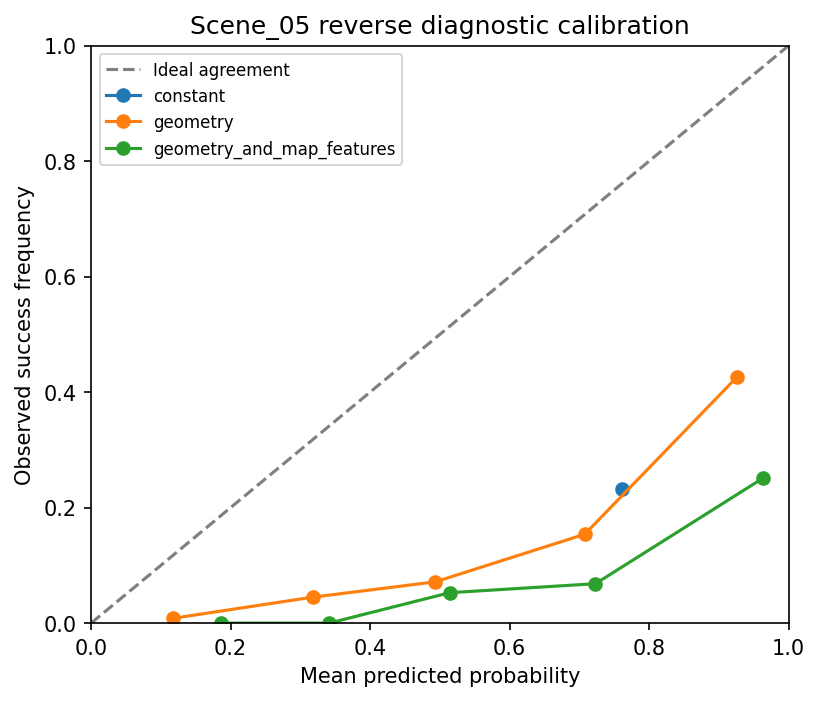

In [3]:
summary = modeling.run_reverse_diagnostic(DATASET_DIR, OUTPUT_DIR)
print('Status:', summary['training_status'])
for name, result in summary['evaluations'].items():
    print(name, {k: result[k] for k in ('sample_count', 'observed_success_rate', 'mean_probability', 'log_loss', 'brier_score', 'roc_auc', 'outside_training_feature_ranges_count')})
from IPython.display import display, Markdown, Image
display(Markdown((OUTPUT_DIR / 'report.md').read_text(encoding='utf-8')))
display(Image(filename=str(OUTPUT_DIR / 'calibration.png')))


## 3. Порівняти обидва напрямки

Таблиця нижче читає збережений перший дослід, не запускаючи його повторно. Помітно різні результати напрямків свідчать про залежність перенесення від навчальної сцени. Це ще не доводить єдину причину відмов.

Кадри сусідні й залежні між собою; два напрямки не є двома незалежними наборами сцен. Ознаки не підбираємо за Scene_21.


In [4]:
FORWARD_DIR = REPO_ROOT / 'vml/correct-fix-model-v1'
if (FORWARD_DIR / 'summary.json').exists():
    forward_run = modeling._read(FORWARD_DIR / 'run.json')
    reverse_run = modeling._read(OUTPUT_DIR / 'run.json')
    if forward_run['dataset_sha256'] != reverse_run['dataset_sha256']:
        raise ValueError('Forward and reverse datasets differ; do not compare these runs.')
    forward = modeling._read(FORWARD_DIR / 'summary.json')
    comparison = ['| Direction | Model | Log loss | Brier | AUC |', '| --- | --- | ---: | ---: | ---: |']
    for direction, results in [('05 to 07', forward['evaluations']), ('07 to 05', summary['evaluations'])]:
        for name, metrics in results.items():
            comparison.append(f"| {direction} | {name} | {metrics['log_loss']:.4f} | {metrics['brier_score']:.4f} | {metrics['roc_auc']:.4f} |")
    display(Markdown('\n'.join(comparison)))
else:
    print('Forward summary is absent; inspect the saved reverse report independently.')


| Direction | Model | Log loss | Brier | AUC |
| --- | --- | ---: | ---: | ---: |
| 05 to 07 | constant | 1.1731 | 0.4610 | 0.5000 |
| 05 to 07 | geometry | 1.7399 | 0.5647 | 0.8164 |
| 05 to 07 | geometry_and_map_features | 2.3346 | 0.5981 | 0.8730 |
| 07 to 05 | constant | 1.1613 | 0.4575 | 0.5000 |
| 07 to 05 | geometry | 1.1119 | 0.3324 | 0.7982 |
| 07 to 05 | geometry_and_map_features | 2.7555 | 0.6607 | 0.6716 |

## Що передати

Збережіть виконаний notebook із виводами. Завантажте **всю нову папку `vml/correct-fix-reverse-v1`** до локальної `results/vml/`.

У папці: конфігурація, зведення, звіт, прогнози, графік і таблиця калібрування, а також три моделі в `evaluation_models/`. Калібрування — відповідність прогнозованих імовірностей фактичній частоті успіху.

Scene_21 цей notebook не читає. Поточний результат призначений для дослідження й не підключає ймовірності до планувальника.
